In [38]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path = '/content/drive/MyDrive/encoded_cleaned_data.csv'

df = pd.read_csv(path)
df.head(10)

,vehicle_brand,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,12,2,2019.0,1,1,82.54,2,98163.0,6.94,1,...,2.0,3.0,0.0,0.00,53.50,66.0,65.20,0.00,401.0,0
1,0,3,2018.0,8,4,64.17,0,113600.0,7.79,1,...,0.0,3.0,0.0,51.00,38.80,67.8,46.30,40.90,1094.0,0
2,17,5,2018.0,3,4,90.92,2,242253.0,7.85,0,...,4.0,1.0,0.0,36.20,66.10,48.6,0.00,6.50,645.0,0
3,18,1,2022.0,1,4,47.35,0,83700.0,6.50,1,...,0.0,3.0,1.0,23.40,32.50,58.2,50.99,40.95,867.0,0
4,16,0,2015.0,0,4,68.04,1,88784.0,11.13,1,...,3.0,2.0,1.0,51.20,45.40,51.0,50.99,100.00,1090.0,0
5,9,2,2018.0,8,0,74.97,0,156939.0,8.06,1,...,0.0,1.0,0.0,49.20,27.70,70.7,49.60,100.00,3258.0,0
6,12,2,2019.0,0,4,76.24,1,185719.0,6.91,0,...,0.0,5.0,0.0,52.90,29.91,48.8,2.70,83.40,784.0,0
7,12,2,2016.0,1,4,92.36,0,110334.0,10.31,1,...,5.0,3.0,2.0,73.30,45.00,44.1,18.20,56.30,1018.0,0
8,2,0,2016.0,7,4,77.77,1,107016.0,10.01,1,...,1.0,0.0,0.0,2.20,48.30,64.9,77.20,0.30,1184.0,0
9,0,2,2024.0,5,4,98.53,0,7051.0,1.89,1,...,1.0,3.0,0.0,35.18,0.00,64.0,91.50,45.00,1458.0,0


In [4]:
X = df.drop(columns='battery_failure', axis=1)
y = df['battery_failure']

In [5]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression())])
rfc = RandomForestClassifier(n_estimators=200,random_state=42)
dtc = DecisionTreeClassifier(random_state=42)
xgc = XGBClassifier(eval_metric='logloss')


In [8]:

lr.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LogisticRegression())])

In [27]:
y_prediction_of_lr = lr.predict(X_test)

accuracy_of_lr = accuracy_score(y_test,y_prediction_of_lr)

print("Accuracy of Logistic Regression:",accuracy_of_lr * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_lr,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE Of Logistic Regression")
print(roc_auc_score(y_test,lr.predict_proba(X_test)[:,1]))

Accuracy of Logistic Regression: 96.7825
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     36169
           1       0.81      0.87      0.84      3831

    accuracy                           0.97     40000
   macro avg       0.90      0.92      0.91     40000
weighted avg       0.97      0.97      0.97     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE Of Logistic Regression
0.9897682321081451


In [18]:
dtc.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [28]:
y_prediction_of_dtc = dtc.predict(X_test)

accuracy_of_dtc = accuracy_score(y_test,y_prediction_of_dtc)

print("Accuracy of Decision Tree Classifier",accuracy_of_dtc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_dtc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of Decision Tree Classifier")
print(roc_auc_score(y_test,dtc.predict_proba(X_test)[:,1]))

Accuracy of Decision Tree Classifier 94.0225
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     35965
           1       0.70      0.71      0.71      4035

    accuracy                           0.94     40000
   macro avg       0.83      0.84      0.84     40000
weighted avg       0.94      0.94      0.94     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of Decision Tree Classifier
0.8342622638334455


In [22]:
rfc.fit(X_train,y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [30]:
y_prediction_of_rfc = rfc.predict(X_test)

accuracy_of_rfc = accuracy_score(y_test,y_prediction_of_rfc)

print("Accuracy Of Random Forest Classifier",accuracy_of_rfc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_rfc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of Random Forest Classifier")
print(roc_auc_score(y_test,rfc.predict_proba(X_test)[:,1]))

Accuracy Of Random Forest Classifier 96.1025
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.99      0.97      0.98     36465
           1       0.74      0.86      0.80      3535

    accuracy                           0.96     40000
   macro avg       0.86      0.91      0.89     40000
weighted avg       0.96      0.96      0.96     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of Random Forest Classifier
0.9856662863701616


In [32]:
xgc.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [33]:
y_prediction_of_xgc = xgc.predict(X_test)

accuracy_of_xgc = accuracy_score(y_test,y_prediction_of_xgc)

print("Accuracy Of XGBoost Classifier",accuracy_of_xgc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_xgc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of XGBoost Classifier")
print(roc_auc_score(y_test,xgc.predict_proba(X_test)[:,1]))

Accuracy Of XGBoost Classifier 96.44749999999999
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     36143
           1       0.80      0.85      0.82      3857

    accuracy                           0.96     40000
   macro avg       0.89      0.91      0.90     40000
weighted avg       0.97      0.96      0.96     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of XGBoost Classifier
0.9878029543515592


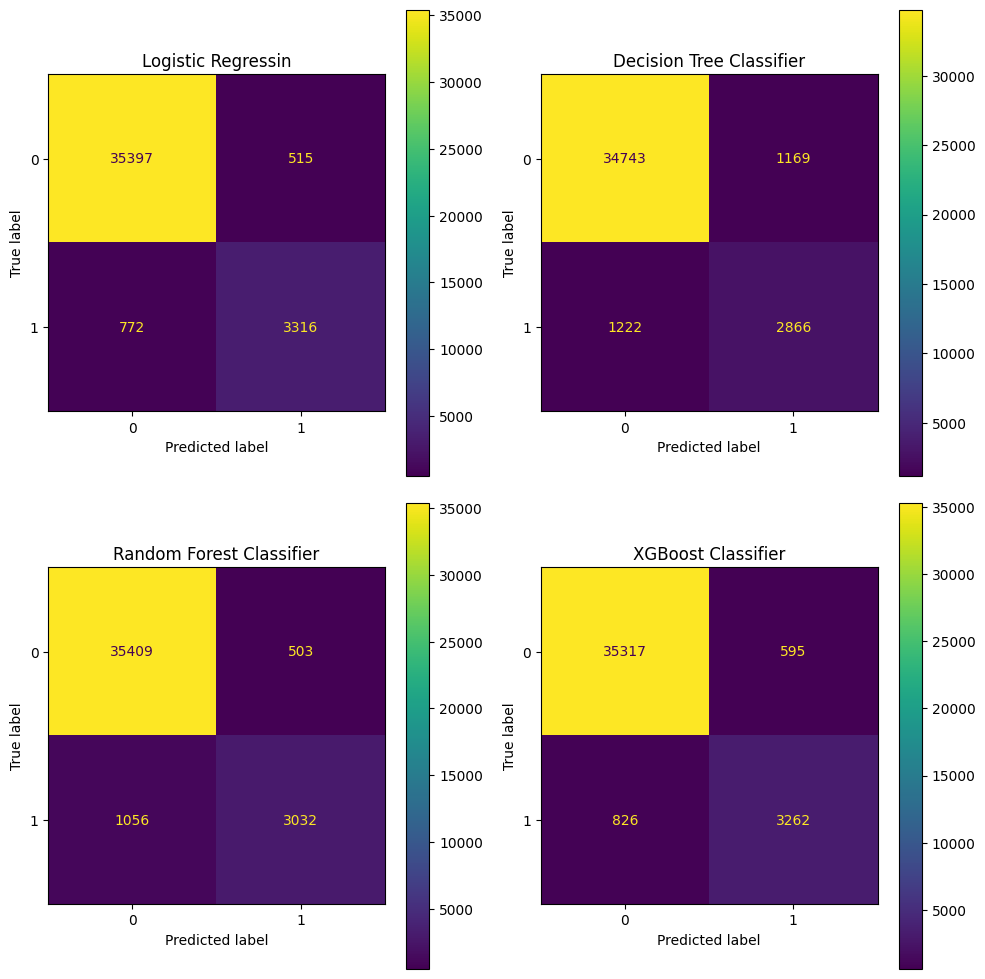

In [58]:
models = [("Logistic Regressin",lr),("Decision Tree Classifier",dtc),("Random Forest Classifier",rfc),("XGBoost Classifier",xgc)]

fig , axes = plt.subplots(2,2, figsize=(10,10))

for ax,(name,model) in zip(axes.ravel(),models):
  ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,ax=ax)
  ax.set_title(name)

plt.tight_layout()
plt.show()